# 03 — Predict the label, assess targeting and seal the test

**Inputs:** the contract and split from 01; training associations from 02. **Outputs:** validation comparisons, a frozen protocol and aggregate test results for 04.

The documented encoding is 1 = departure, 0 = no observed departure. The contract does not establish chronology: this retrospective comparison validates neither a prospective score nor an annual horizon. A dated cohort is still required before use. No substitute target is constructed.

The independent review of 02 was closed before this step. The choices below precede analytical access to the test set in the original study. Reruns check the frozen protocol and read cached test results; they do not reevaluate the test.

**English edition:** only presentation has changed. `translation_provenance.json` records the exact translated code fingerprints and original artifact fingerprints, while the original protocol and test cache remain sealed. Legacy internal artifact labels are translated at display time.

In [1]:
from pathlib import Path
import json, hashlib, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown
ROOT = Path.cwd() if (Path.cwd() / 'brief.md').exists() else Path.cwd().parent
assert (ROOT / 'brief.md').exists(), 'Run from the project root or notebooks/'
sys.path.insert(0, str(ROOT / 'src'))
from presentation import display, en
SEED = 42
OUT = ROOT / 'data/results'
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.figsize': (9, 5), 'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})
def sha(path): return hashlib.sha256(Path(path).read_bytes()).hexdigest()

## Comparison plan, decided outside the test set

- Naive baseline: a constant probability equal to training prevalence.
- Logistic regression: C=1, standardized numerical predictors and encoded categories.
- Random forest: 300 trees, maximum depth 10, minimum leaf size 10, seed 42. These simple settings were not selected on the test set.
- The five numerical features are median-imputed and standardized. Country, product count, card and activity indicators are imputed with the most frequent category and one-hot encoded. Every learned transformation is inside a pipeline. Gender is excluded as decided in 02; names, identifiers and the technical key are also excluded. No resampling or class weighting is applied, to retain interpretable probabilities.
- Select the logistic/forest family by **validation average precision (AP)**, breaking a tie by lower Brier score. Then train its sigmoid-calibrated variant using out-of-fold training predictions (five stratified folds, with preprocessing relearned within each fold). Keep calibration if validation Brier improves and AP falls by no more than 0.01. Neither validation nor test data are used to fit calibration; validation selects the variant.
- Illustrative capacity: contact the top 20% in each batch. This capacity is not optimized. Ties use a pseudorandom ordering with seed 42, independent of the target. The validation score cutoff is descriptive; the simulated policy uses a quota, not that numerical cutoff.

ROC-AUC measures overall ranking. AP summarizes precision–recall and is compared with prevalence. Brier measures squared probability error (lower is better). Precision, recall and lift at the quota assess the concentration of departure labels, not campaign effectiveness.

In [2]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, roc_curve, precision_recall_curve
import importlib.metadata
import nbformat
contract=json.loads((ROOT/'data/processed/contract.json').read_text())
assert contract['target']=='Exited' and contract['positive_class']==1 and contract['definition']
assert sha(ROOT/'data/raw/Churn_Modelling.csv')==contract['raw_sha256']
assert sha(ROOT/'data/processed/splits.csv')==contract['split_sha256']
data_path=ROOT/'data/processed/customers.csv'
base=pd.read_csv(data_path)
splits=pd.read_csv(ROOT/'data/processed/splits.csv')
assert base.observation_id.is_unique and splits.observation_id.is_unique
train=base.merge(splits.query("split == 'train'"),on='observation_id',validate='one_to_one')
val=base.merge(splits.query("split == 'validation'"),on='observation_id',validate='one_to_one')
# Select test rows and their target only in the final evaluation cell.
del base,splits
num=['CreditScore','Age','Tenure','Balance','EstimatedSalary']
cat=['Geography','NumOfProducts','HasCrCard','IsActiveMember']
features=num+cat
Xtr,ytr=train[features],train.Exited
Xv,yv=val[features],val.Exited
assert len(train)==6000 and len(val)==2000
assert set(ytr)==set(yv)=={0,1}
pre=ColumnTransformer([
 ('num',Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())]),num),
 ('cat',Pipeline([('impute',SimpleImputer(strategy='most_frequent')),('encode',OneHotEncoder(handle_unknown='ignore',sparse_output=False))]),cat)
])
models={
 'Naïf':Pipeline([('pre',clone(pre)),('model',DummyClassifier(strategy='prior'))]),
 'Logistique':Pipeline([('pre',clone(pre)),('model',LogisticRegression(C=1,max_iter=2000,random_state=SEED))]),
 'Forêt':Pipeline([('pre',clone(pre)),('model',RandomForestClassifier(n_estimators=300,max_depth=10,min_samples_leaf=10,random_state=SEED,n_jobs=1))])
}
CAPACITY=.20
def top_indices(scores,k):
 scores=np.asarray(scores)
 tie=np.random.default_rng(SEED).random(len(scores))
 return np.lexsort((tie,-scores))[:k]
def metrics(y,p):
 y=np.asarray(y);p=np.asarray(p);k=int(np.floor(CAPACITY*len(y)))
 idx=top_indices(p,k);tp=int(y[idx].sum());prev=float(y.mean())
 return {'n':len(y),'positifs':int(y.sum()),'roc_auc':float(roc_auc_score(y,p)), 'average_precision':float(average_precision_score(y,p)), 'brier':float(brier_score_loss(y,p)), 'contacts':k,'departs_contactes':tp,'precision_budget':tp/k,'rappel_budget':tp/int(y.sum()),'lift_budget':(tp/k)/prev,'probabilite_moyenne':float(p.mean()),'prevalence':prev}
val_probs={}
for name,model in models.items():
 model.fit(Xtr,ytr)
 assert model.classes_.tolist()==[0,1]
 val_probs[name]=model.predict_proba(Xv)[:,1]
val_metrics=pd.DataFrame({name:metrics(yv,p) for name,p in val_probs.items()}).T
family=val_metrics.loc[['Logistique','Forêt']].sort_values(['average_precision','brier'],ascending=[False,True]).index[0]
cal_name=family+' sigmoid'
models[cal_name]=CalibratedClassifierCV(estimator=clone(models[family]),method='sigmoid',cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED),ensemble=False,n_jobs=1)
models[cal_name].fit(Xtr,ytr)
val_probs[cal_name]=models[cal_name].predict_proba(Xv)[:,1]
val_metrics.loc[cal_name]=pd.Series(metrics(yv,val_probs[cal_name]))
use_cal=val_metrics.loc[cal_name,'brier']<val_metrics.loc[family,'brier'] and val_metrics.loc[cal_name,'average_precision']>=val_metrics.loc[family,'average_precision']-.01
selected=cal_name if use_cal else family
val_metrics.index.name='modele'
display(val_metrics.round(4))
print('Family selected by validation AP:',en(family),'; selected variant:',en(selected))

Family selected by validation AP: Random forest ; selected variant: Random forest (sigmoid)


,n,Positive labels,ROC-AUC,Average precision,Brier score,Contacts,Churn labels targeted,Precision at budget,Recall at budget,Lift at budget,Mean predicted probability,Prevalence
Model,,,,,,,,,,,,
Naive baseline,2000.0,408.0,0.5000,0.2040,0.1624,400.0,74.0,0.185,0.1814,0.9069,0.2037,0.204
Logistic regression,2000.0,408.0,0.8440,0.6344,0.1132,400.0,240.0,0.600,0.5882,2.9412,0.2079,0.204
Random forest,2000.0,408.0,0.8725,0.7067,0.1010,400.0,262.0,0.655,0.6422,3.2108,0.2142,0.204
Random forest (sigmoid),2000.0,408.0,0.8725,0.7067,0.0996,400.0,262.0,0.655,0.6422,3.2108,0.2153,0.204


## Validation calibration

Points compare mean predicted probability with observed frequency in score intervals of width 0.1. The table reports sample sizes: small bins can fluctuate substantially. Brier combines discrimination and calibration and cannot alone establish perfect calibration. No adjustment uses the test set.

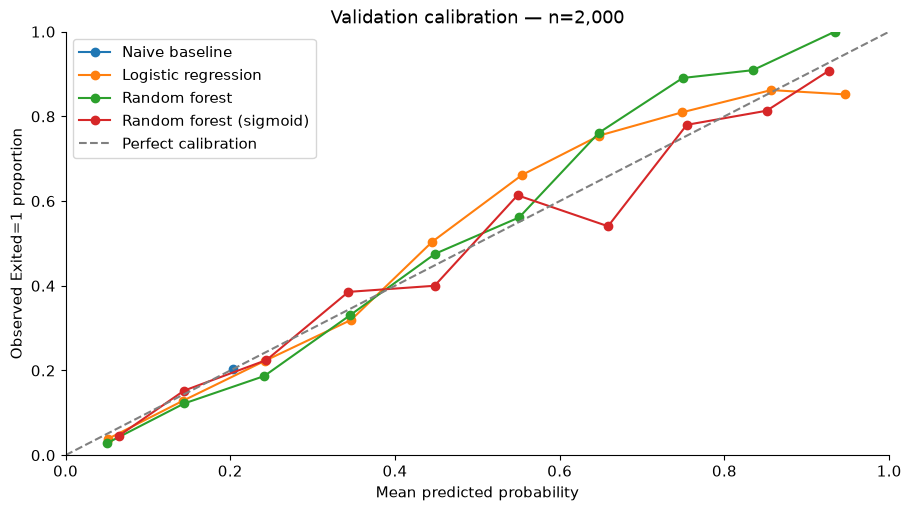

,Score interval,n,Churn labels,Mean predicted probability,Observed proportion
0,"(-0.001, 0.1]",1040,47,0.0644,0.0452
1,"(0.1, 0.2]",407,62,0.1438,0.1523
2,"(0.2, 0.3]",138,31,0.2440,0.2246
3,"(0.3, 0.4]",83,32,0.3434,0.3855
4,"(0.4, 0.5]",50,20,0.4481,0.4000
5,"(0.5, 0.6]",44,27,0.5488,0.6136
6,"(0.6, 0.7]",37,20,0.6587,0.5405
7,"(0.7, 0.8]",50,39,0.7542,0.7800
8,"(0.8, 0.9]",75,61,0.8513,0.8133
9,"(0.9, 1.0]",76,69,0.9269,0.9079


In [3]:
def calibration_table(y,p):
 d=pd.DataFrame({'y':np.asarray(y),'p':np.asarray(p)})
 d['intervalle']=pd.cut(d.p,np.linspace(0,1,11),include_lowest=True)
 t=d.groupby('intervalle',observed=True).agg(n=('y','size'),departs=('y','sum'),probabilite=('p','mean'),observe=('y','mean')).reset_index()
 t['intervalle']=t.intervalle.astype(str)
 return t
fig,ax=plt.subplots(layout='constrained')
for name,p in val_probs.items():
 t=calibration_table(yv,p)
 ax.plot(t.probabilite,t.observe,'o-',label=en(name))
ax.plot([0,1],[0,1],'--',color='gray',label='Perfect calibration')
ax.set(xlabel='Mean predicted probability',ylabel='Observed Exited=1 proportion',title='Validation calibration — n=2,000',xlim=(0,1),ylim=(0,1))
ax.legend();plt.show()
display(calibration_table(yv,val_probs[selected]).round(4))

## Freeze before opening the test set

Four prespecified strategies: no contact; random targeting (fixed draw, seed 42); a business rule (score = 2 × inactive + 1 × age ≥45 years); and predictive targeting (the selected model's score). The simple business rule reflects training associations and is not optimized on the test set. The three campaigns contact exactly 20% of the same batch and incur the same cost per contact.

**Illustrative economic scenario, without campaign data:** economic horizon H=12 months; contact cost €2 plus an €8 offer paid to every contacted customer; €500 in net margin preserved per prevented departure over H, excluding campaign costs; fraction of departures prevented q=20%. Total cost is €10 per contact, capped at €4,000 for 400 contacts in a batch of 2,000. These values are neither supplied by the brief nor estimated.

Simulation over H assumes that labels represent departure risk without a new campaign over that horizon, that all customers are eligible and reachable, that non-departing customers are unaffected, and that there is no interference. This temporal transfer is **unverified**. q is an assumed fraction of departures that would otherwise occur, not a 20-percentage-point absolute reduction or measured uplift. Margin is homogeneous and unrelated to balance. Simulated net gain is `q × margin × targeted departure labels − cost × contacts`.

The sensitivity grid is fixed here: q ∈ {0, 0.1, 0.2, 0.4}, margin ∈ {250,500,1000} euros, total cost ∈ {5,10,20} euros. Including q=0 exposes a loss equal to campaign cost. No scenario changes targeting. Test statistics describe one holdout and do not demonstrate retention effectiveness.

In [4]:
kval=int(CAPACITY*len(val))
threshold=float(np.sort(val_probs[selected])[::-1][kval-1])
notebook=nbformat.read(ROOT/'notebooks/03-prediction.ipynb',as_version=4)
pretest_sources=[]
for cell in notebook.cells:
 if cell.cell_type=='code':
  if cell.source.startswith('# FINAL_EVALUATION'): break
  pretest_sources.append(cell.source)
code_hash=hashlib.sha256('\n'.join(pretest_sources).encode()).hexdigest()
# The English edition preserves the original scientific protocol and cached test.
# Its exact code and presentation fingerprints are recorded in an editorial manifest.
editorial = json.loads((OUT / 'translation_provenance.json').read_text())
assert code_hash == editorial['english_pretest_code_sha256'], 'Unreviewed code change in the English edition'
assert sha(ROOT / 'src/presentation.py') == editorial['presentation_sha256']
for artifact, expected_hash in editorial['original_artifact_sha256'].items():
 assert sha(ROOT / artifact) == expected_hash, f'Original study artifact changed: {artifact}'
for name, expected_hash in editorial['english_notebook_code_sha256'].items():
 cells = nbformat.read(ROOT / 'notebooks' / name, as_version=4).cells
 actual_hash = hashlib.sha256('\n'.join(c.source for c in cells if c.cell_type == 'code').encode()).hexdigest()
 assert actual_hash == expected_hash, f'Unreviewed notebook code change: {name}'
# Only the editorial fingerprint changed; all fitted-model and validation checks below remain active.
code_hash = editorial['original_pretest_code_sha256']
freeze={
 'seed':SEED,'data_sha256':sha(data_path),'raw_sha256':contract['raw_sha256'],'split_sha256':contract['split_sha256'],
 'pretest_code_sha256':code_hash,'features':features,'selected_model':selected,
 'models':{name:repr(model) for name,model in models.items()},
 'validation_scores_sha256':hashlib.sha256(np.column_stack(list(val_probs.values())).tobytes()).hexdigest(),
 'selection_rule':'famille AP validation, puis sigmoid si Brier améliore et perte AP <= 0.01',
 'capacity':CAPACITY,'validation_cutoff_descriptive':threshold,
 'target_policy':'quota top 20%, égalités pseudo-aléatoires graine 42, sans identifiant métier',
 'business_rule':'2*(IsActiveMember==0) + 1*(Age>=45)',
 'random_rule':'uniforme, graine 42 ; un tirage figé, pas le meilleur de plusieurs',
 'strategies':['Aucun contact','Aléatoire','Métier','Prédictif'],
 'economics':{'hypothetical':True,'economic_horizon_months':12,'label_horizon_verified':False,'contact_cost_eur':2,'offer_cost_eur_all_contacts':8,'cost_eur':10,'margin_eur':500,'q':.2,'effects':[0,.1,.2,.4],'margins':[250,500,1000],'costs':[5,10,20]},
 'test_plan':'tous modèles figés, quatre stratégies, calibration du retenu ; bootstrap 1000 du retenu ; aucun choix sur test',
 'versions':{p:importlib.metadata.version(p) for p in ['numpy','pandas','scikit-learn','scipy']}
}
freeze_path=OUT/'frozen_protocol.json'
if freeze_path.exists():
 assert json.loads(freeze_path.read_text())==freeze, 'Protocol changed after freezing: the test is closed; do not delete its cache to tune on test data.'
else:
 freeze_path.write_text(json.dumps(freeze,ensure_ascii=False,indent=2))
freeze_hash=sha(freeze_path)
val_metrics.to_csv(OUT/'validation_metrics.csv')
print('Protocol frozen before test; model:',en(selected))
print(f'Validation quota: {kval} customers; descriptive cutoff = {threshold:.4f}.')
print('Frozen protocol fingerprint:',freeze_hash)

Protocol frozen before test; model: Random forest (sigmoid)
Validation quota: 400 customers; descriptive cutoff = 0.3108.
Frozen protocol fingerprint: e2e57546c1df723f56d8b5affb50ad7edd310d8538816b821738538c0a3e9f87


In [5]:
# FINAL_EVALUATION — original single opening; reruns read the aggregate cache.
result_path=OUT/'test_evaluation.json'
if result_path.exists():
 result=json.loads(result_path.read_text())
 assert result['freeze_sha256']==freeze_hash
 print('Final results read from cache: no new test evaluation.')
else:
 test=pd.read_csv(data_path).merge(pd.read_csv(ROOT/'data/processed/splits.csv').query("split == 'test'"),on='observation_id',validate='one_to_one')
 assert len(test)==2000 and set(test.Exited)=={0,1}
 Xt,yt=test[features],test.Exited.to_numpy()
 test_probs={name:model.predict_proba(Xt)[:,1] for name,model in models.items()}
 test_metrics={name:metrics(yt,p) for name,p in test_probs.items()}
 p=test_probs[selected];k=int(CAPACITY*len(test))
 random_scores=np.random.default_rng(SEED).random(len(test))
 business_scores=2*test.IsActiveMember.eq(0).astype(int).to_numpy()+test.Age.ge(45).astype(int).to_numpy()
 policies={'Aucun contact':np.array([],dtype=int),'Aléatoire':top_indices(random_scores,k),'Métier':top_indices(business_scores,k),'Prédictif':top_indices(p,k)}
 strategies=[]
 for name,idx in policies.items():
  contacts=len(idx);tp=int(yt[idx].sum())
  strategies.append({'strategie':name,'population':len(test),'positifs_population':int(yt.sum()),'contacts':contacts,'departs_contactes':tp,'precision':tp/contacts if contacts else None,'rappel':tp/int(yt.sum()),'lift':(tp/contacts)/yt.mean() if contacts else None,'cout_scenario_eur':contacts*freeze['economics']['cost_eur'],'gain_net_scenario_eur':freeze['economics']['q']*freeze['economics']['margin_eur']*tp-freeze['economics']['cost_eur']*contacts})
 # Descriptive bootstrap with a fixed model: no retraining or selection.
 rng=np.random.default_rng(SEED)
 boot=[]
 for _ in range(1000):
  ix=rng.integers(0,len(yt),len(yt))
  boot.append(metrics(yt[ix],p[ix]))
 boot=pd.DataFrame(boot)
 intervals={m:{'bas':float(boot[m].quantile(.025)),'haut':float(boot[m].quantile(.975))} for m in ['roc_auc','average_precision','brier','precision_budget','rappel_budget','lift_budget']}
 fpr,tpr,_=roc_curve(yt,p)
 precision,recall,_=precision_recall_curve(yt,p)
 result={'freeze_sha256':freeze_hash,'selected_model':selected,'n_test':len(test),'positifs_test':int(yt.sum()),'metrics':test_metrics,'strategies':strategies,'selected_bootstrap_ic95':intervals,'selected_calibration':calibration_table(yt,p).to_dict(orient='records'),'roc':{'fpr':fpr.tolist(),'tpr':tpr.tolist()},'pr':{'precision':precision.tolist(),'recall':recall.tolist()},'random_expected_departures':float(k*yt.mean()),'scope':'holdout rétrospectif ; scénarios non causaux, horizon label inconnu'}
 result_path.write_text(json.dumps(result,ensure_ascii=False,indent=2))
 del test,Xt,yt,test_probs,p,policies
final_metrics=pd.DataFrame(result['metrics']).T
final_metrics.index.name='modele'
display(final_metrics.round(4))
display(pd.DataFrame(result['selected_bootstrap_ic95']).T.rename(columns={'bas':'95% CI lower','haut':'95% CI upper'}).round(4))
display(pd.DataFrame(result['strategies']).round(4))

Final results read from cache: no new test evaluation.


,n,Positive labels,ROC-AUC,Average precision,Brier score,Contacts,Churn labels targeted,Precision at budget,Recall at budget,Lift at budget,Mean predicted probability,Prevalence
Model,,,,,,,,,,,,
Naive baseline,2000.0,407.0,0.5000,0.2035,0.1621,400.0,79.0,0.1975,0.1941,0.9705,0.2037,0.2035
Logistic regression,2000.0,407.0,0.8325,0.6268,0.1150,400.0,232.0,0.5800,0.5700,2.8501,0.2022,0.2035
Random forest,2000.0,407.0,0.8567,0.6853,0.1053,400.0,248.0,0.6200,0.6093,3.0467,0.2064,0.2035
Random forest (sigmoid),2000.0,407.0,0.8567,0.6853,0.1053,400.0,248.0,0.6200,0.6093,3.0467,0.2062,0.2035


,95% CI lower,95% CI upper
ROC-AUC,0.8346,0.8770
Average precision,0.6344,0.7274
Brier score,0.0956,0.1144
Precision at budget,0.5600,0.6725
Recall at budget,0.5738,0.6506
Lift at budget,2.8692,3.2532


,Strategy,Population,Population positive labels,Contacts,Churn labels targeted,Precision,Recall,Lift,Scenario cost (€),Scenario net gain (€)
0,No contact,2000,407,0,0,NaN,0.0000,NaN,0,0.0
1,Random,2000,407,400,85,0.2125,0.2088,1.0442,4000,4500.0
2,Business rule,2000,407,400,169,0.4225,0.4152,2.0762,4000,12900.0
3,Predictive,2000,407,400,248,0.6200,0.6093,3.0467,4000,20800.0


## Final interpretation and limitations

Bootstrap intervals (1,000 resamples of test customers, seed 42) describe holdout uncertainty conditional on the fixed model and choices. They do not cover training uncertainty, model selection or drift. The quota is reapplied within each resample.

Test comparisons of candidates are reported as planned. The selected model remains the one chosen on validation even if another candidate performs better on a test metric. Economic tables are counterfactual simulations under assumptions, without observed campaigns. Outputs are aggregated; no customer list or individual probability is exported.

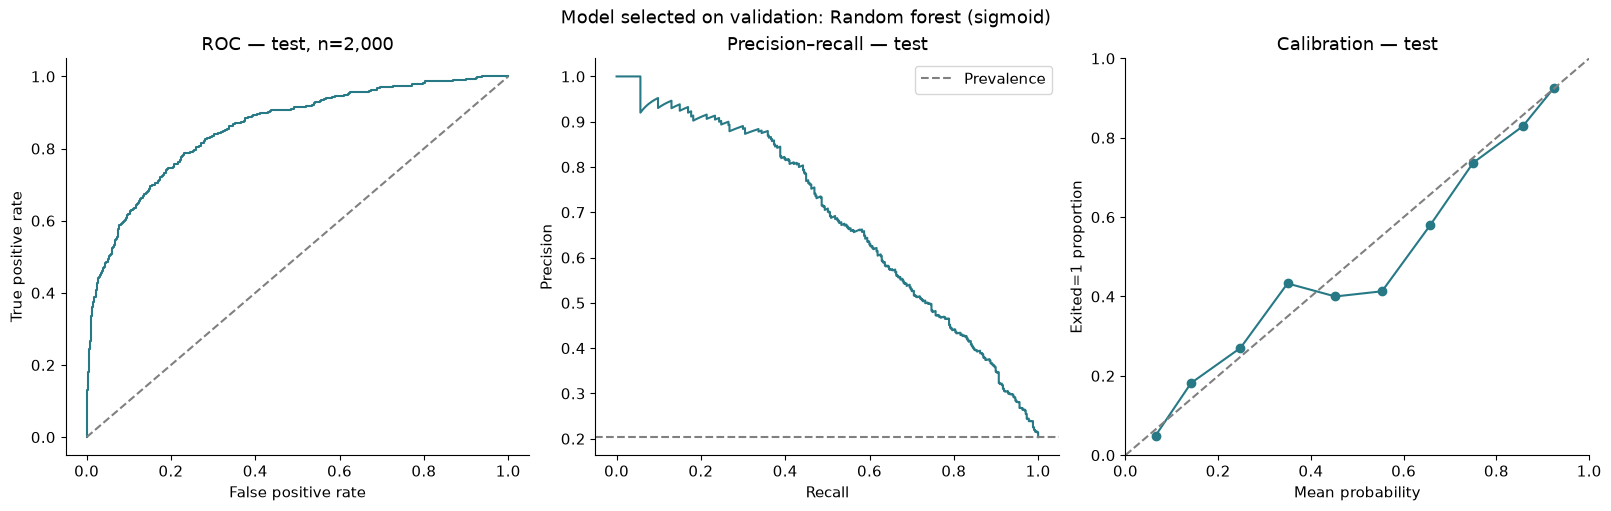

,Score interval,n,Churn labels,Mean predicted probability,Observed proportion
0,"(-0.001, 0.1]",1072,53,0.0650,0.0494
1,"(0.1, 0.2]",407,74,0.1415,0.1818
2,"(0.2, 0.3]",148,40,0.2480,0.2703
3,"(0.3, 0.4]",67,29,0.3495,0.4328
4,"(0.4, 0.5]",40,16,0.4525,0.4000
5,"(0.5, 0.6]",46,19,0.5532,0.4130
6,"(0.6, 0.7]",38,22,0.6567,0.5789
7,"(0.7, 0.8]",38,28,0.7498,0.7368
8,"(0.8, 0.9]",76,63,0.8568,0.8289
9,"(0.9, 1.0]",68,63,0.9246,0.9265


### Handoff to the decision-maker

Frozen model: **Random forest (sigmoid)**. On this retrospective test, ROC-AUC is **0.857**, AP **0.685**, and Brier **0.105**. At the 20% quota (400 contacts), precision is **62.0%**, recall **60.9%**, and lift **3.05**.

Notebook 04 uses aggregate results and the frozen protocol only. Economic differences follow from homogeneous assumptions and counts of positive labels targeted; they demonstrate neither offer response nor actual profitability. Missing chronology may overstate prospective performance: confirm feature availability before departure and test on a future cohort before launching a campaign.


In [6]:
fig,axes=plt.subplots(1,3,figsize=(16,5),layout='constrained')
axes[0].plot(result['roc']['fpr'],result['roc']['tpr'],color='#267985');axes[0].plot([0,1],[0,1],'--',color='gray')
axes[0].set(xlabel='False positive rate',ylabel='True positive rate',title='ROC — test, n=2,000')
axes[1].plot(result['pr']['recall'],result['pr']['precision'],color='#267985')
axes[1].axhline(result['positifs_test']/result['n_test'],linestyle='--',color='gray',label='Prevalence')
axes[1].set(xlabel='Recall',ylabel='Precision',title='Precision–recall — test');axes[1].legend()
t=pd.DataFrame(result['selected_calibration'])
axes[2].plot(t.probabilite,t.observe,'o-',color='#267985');axes[2].plot([0,1],[0,1],'--',color='gray')
axes[2].set(xlabel='Mean probability',ylabel='Exited=1 proportion',title='Calibration — test',xlim=(0,1),ylim=(0,1))
fig.suptitle('Model selected on validation: '+en(selected))
plt.show()
display(t.round(4))
r=result['metrics'][selected]
display(Markdown(f"""### Handoff to the decision-maker

Frozen model: **{en(selected)}**. On this retrospective test, ROC-AUC is **{r['roc_auc']:.3f}**, AP **{r['average_precision']:.3f}**, and Brier **{r['brier']:.3f}**. At the 20% quota ({r['contacts']} contacts), precision is **{r['precision_budget']:.1%}**, recall **{r['rappel_budget']:.1%}**, and lift **{r['lift_budget']:.2f}**.

Notebook 04 uses aggregate results and the frozen protocol only. Economic differences follow from homogeneous assumptions and counts of positive labels targeted; they demonstrate neither offer response nor actual profitability. Missing chronology may overstate prospective performance: confirm feature availability before departure and test on a future cohort before launching a campaign.
"""))